<a href="https://colab.research.google.com/github/benallsup98/murine_macrophage_proteomics_data/blob/main/Gudgeon_Trost_macrophage_models_proteomics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Murine macrophage line comparison: protein abundance plot

### This colab notebook plots data from Gudgeon et al. Life Sci Alliance. 2024 which compares the proteome of various murine macrophage models.

### How to use:

1.   Press the "play button" on the first two hidden cells to download the dataset and define all necessary functions
2.   Adjust the variable "query" at the top of each plotting cell as a list to contain your genes of interest. Capitalization does not matter.
3. Run either plot (waterfall or heatmap) to be your proteins of interest. Set SAVE = True if you want to save the output



In [1]:
# @title Import and confirm data
# Trost et al. murine macrophage proteomics: WT BMDM vs WT iBMDM, J774A.1, RAW264.7, BMA3.1A7.
# Heatmap values = mean of the 4 raw-intensity replicates per macrophage type, log10-transformed.

import re
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("white")

# ---- paths ------------------------------------------------------------------
XLSX_PATH    = "trost_murine-macrophage-comparison-proteomics.xlsx"
DATA_SHEET   = "Cell_lines_vs_C57BL6J_BMDM"
LEGEND_SHEET = "Legend"
SAVE         = False          # flip to True to write PNGs passed as savepath=

# download raw file from Ben's github using ?raw=true ONLY if it doesn't already exist
if not os.path.exists(XLSX_PATH):
    print(f"{XLSX_PATH} not found. Downloading...")
    !wget -O {XLSX_PATH} "https://github.com/benallsup98/murine_macrophage_proteomics_data/blob/main/trost_murine-macrophage-comparison-proteomics.xlsx?raw=true"
else:
    print(f"{XLSX_PATH} already exists. Skipping download.")

# ---- replicate-column prefix -> heatmap column label (dict order = column order; reference BMDM first)
CELL_LINES = {
    "C57BL/6_WT_BMDM":  "Primary BMDM",
    "C57BL/6_WT_iBMDM": "iBMDM",
    "J774A.1":          "J774A.1",
    "RAW264.7":         "RAW264.7",
    "BMA3.1A7":         "BMA3.1A7",
}
N_REPS = 4                    # replicates per line (_R1.._R4)
MIN_REPS = 1                  # a line's mean is NaN unless >= this many replicates were quantified

# ---- shared protein groups ("Cul4a;Cul4b") ------------------------------------
# Rows quantified from peptides shared by several genes are kept as their own heatmap rows (never summed
# into or split across the member genes) and are returned whenever any member gene is queried.
# Label format only: if every member is <same stem> + one of these letters (case-insensitive) the label is
# compressed to "Cul4a/b"; otherwise members are joined with "/" ("Hras/Kras/Nras").
PARALOG_SUFFIXES = "abc"

ID_COLS = ["Uniprot Accession", "Uniprot ID", "Protein name", "Gene name", "Peptide Count"]

xl = pd.ExcelFile(XLSX_PATH)
print("sheets:", xl.sheet_names)

# Legend has no header row -> header=None. Data sheet has a header row.
legend = xl.parse(LEGEND_SHEET, header=None)
raw    = xl.parse(DATA_SHEET, na_values=["NA"], keep_default_na=False)   # "NA" strings -> NaN

# ncols per sheet, checked before any column mapping is used
for name, frame in [(LEGEND_SHEET, legend), (DATA_SHEET, raw)]:
    print(f"{name!r}: {frame.shape[0]:,} rows x {frame.shape[1]} cols")

# full header, printed once, unsliced
print(list(raw.columns))

#load xlsx and verify import
# ---- fail loud if the expected columns are not there --------------------------
missing_id = [c for c in ID_COLS if c not in raw.columns]
if missing_id:
    raise KeyError(f"identifier columns missing from {DATA_SHEET!r}: {missing_id}")

REP_COLS = {line: [f"{line}_R{i}" for i in range(1, N_REPS + 1)] for line in CELL_LINES}
ALL_REP_COLS = [c for cols in REP_COLS.values() for c in cols]

absent = [c for c in ALL_REP_COLS if c not in raw.columns]
if absent:
    raise KeyError(f"replicate columns missing: {absent}")

# any replicate-looking column not covered by CELL_LINES means the mapping above is incomplete
unmapped = [c for c in raw.columns if re.search(r"_R\d+$", c) and c not in ALL_REP_COLS]
if unmapped:
    raise KeyError(f"replicate columns not assigned to a line in CELL_LINES: {unmapped}")

non_numeric = [c for c in ALL_REP_COLS if not pd.api.types.is_numeric_dtype(raw[c])]
if non_numeric:
    raise TypeError(f"non-numeric values in intensity columns (unexpected strings?): {non_numeric}")

nonpos = int((raw[ALL_REP_COLS] <= 0).sum().sum())
if nonpos:
    raise ValueError(f"{nonpos} intensity values <= 0; log transform would be undefined")

# ---- cross-check data header against the Legend's column names (informational) ----
legend_names = set(legend[0].astype(str).str.strip())
#print("in data, not in Legend:", sorted(set(raw.columns) - legend_names))
#print("in Legend, not in data:", sorted(legend_names - set(raw.columns)))

# ---- per-sample sanity: median log10 intensity (raw values; should be comparable across samples) ----
#print(np.log10(raw[ALL_REP_COLS]).median().round(2).to_string())

trost_murine-macrophage-comparison-proteomics.xlsx not found. Downloading...
--2026-10-19 19:57:03--  https://github.com/benallsup98/murine_macrophage_proteomics_data/blob/main/trost_murine-macrophage-comparison-proteomics.xlsx?raw=true
Resolving github.com (github.com)... 140.82.114.3
Connecting to github.com (github.com)|140.82.114.3|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://github.com/benallsup98/murine_macrophage_proteomics_data/raw/refs/heads/main/trost_murine-macrophage-comparison-proteomics.xlsx [following]
--2026-10-19 19:57:03--  https://github.com/benallsup98/murine_macrophage_proteomics_data/raw/refs/heads/main/trost_murine-macrophage-comparison-proteomics.xlsx
Reusing existing connection to github.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://raw.githubusercontent.com/benallsup98/murine_macrophage_proteomics_data/refs/heads/main/trost_murine-macrophage-comparison-proteomics.xlsx [following]
--2026-1

In [2]:
# @title Background functions: Build protein table, Query matching, abundance matrix, plotting functions (heatmap and waterfall)

def _paralog_parts(members, suffixes=PARALOG_SUFFIXES):
    """(stem, sorted letters) if every member is <same stem><one letter in suffixes>, else None."""
    if len(members) < 2 or any(len(m) < 2 for m in members):
        return None
    stems   = {m[:-1].upper() for m in members}
    letters = {m[-1].lower() for m in members}
    if len(stems) != 1 or not letters <= set(suffixes.lower()):
        return None
    return members[0][:-1], sorted(letters)


def _classify(gene_name, uniprot_id):
    """-> (kind, display label, member list)

    kind: 'single'        one gene name
          'paralog_group' e.g. Cul4a;Cul4b   -> label 'Cul4a/b'
          'mixed_group'   e.g. Hras;Kras;Nras -> label 'Hras/Kras/Nras'
          'no_gene_name'  no gene name in the file -> label is the UniProt ID (e.g. IFIT2_MOUSE)
    """
    g = "" if pd.isna(gene_name) else str(gene_name).strip()
    if not g:
        return "no_gene_name", str(uniprot_id).strip(), []
    members = [m.strip() for m in g.split(";") if m.strip()]
    if len(members) == 1:
        return "single", members[0], members
    par = _paralog_parts(members)
    if par:
        stem, letters = par
        return "paralog_group", stem + "/".join(letters), members
    return "mixed_group", "/".join(members), members


def build_protein_table(raw, min_reps=MIN_REPS):
    """One row per display label, indexed by upper-cased label (the case-insensitive lookup key).

    Columns: label, kind, members, raw gene string, identifiers, per-line mean intensity,
    per-line n quantified replicates.
    When several rows share a label (isoforms / protein groups, e.g. Rtn4 x4), the row with the
    most peptides is kept. Peptide-count ties are broken by more quantified replicates, then higher
    summed intensity, and are reported.
    """
    t = raw[ID_COLS].copy()
    cls = [_classify(g, u) for g, u in zip(raw["Gene name"], raw["Uniprot ID"])]
    t["kind"]      = [c[0] for c in cls]
    t["label"]     = [c[1] for c in cls]
    t["members"]   = [c[2] for c in cls]
    t["label_key"] = t["label"].str.upper()
    t["raw_key"]   = raw["Gene name"].astype("string").str.strip().str.upper()   # alias, e.g. CUL4A;CUL4B

    for line, disp in CELL_LINES.items():
        vals = raw[REP_COLS[line]]
        n = vals.notna().sum(axis=1)
        t[f"n_{disp}"] = n
        t[disp] = vals.mean(axis=1).where(n >= min_reps)     # mean on the raw (linear) scale

    t["n_quant"]         = raw[ALL_REP_COLS].notna().sum(axis=1)
    t["total_intensity"] = raw[ALL_REP_COLS].sum(axis=1)

    # ---- collapse duplicate labels: most peptides wins ----
    t = t.sort_values(["label_key", "Peptide Count", "n_quant", "total_intensity"],
                      ascending=[True, False, False, False], kind="mergesort")
    top = t.groupby("label_key")["Peptide Count"].transform("max")
    ties = t[t["Peptide Count"] == top].groupby("label_key").size()
    ties = ties[ties > 1]
    if len(ties):
        print(f"[warn] {len(ties)} label(s) have a peptide-count tie; kept the row with more quantified "
              f"replicates, then higher summed intensity: {', '.join(ties.index)}")

    n_dup_labels = int(t["label_key"].duplicated(keep=False).groupby(t["label_key"]).any().sum())
    kept = t.drop_duplicates("label_key", keep="first").set_index("label_key", drop=False)
    print(f"{len(raw):,} rows -> {len(kept):,} labels "
          f"({n_dup_labels} labels had >1 row; {len(raw) - len(kept)} rows dropped)")
    print(kept["kind"].value_counts().to_string())
    return kept


def build_query_index(proteins):
    """Lookup tables (all keys upper-cased):
    alias         raw semicolon string -> group label key    ('CUL4A;CUL4B' -> 'CUL4A/B')
    group_member  member gene -> [group label keys]          ('CUL4A' -> ['CUL4A/B'], 'HRAS' -> ['HRAS/KRAS/NRAS'])
    Covers both paralog and mixed shared groups.
    """
    alias, group_member = {}, {}
    for key, row in proteins.iterrows():
        if row["kind"] in ("paralog_group", "mixed_group"):
            alias[row["raw_key"]] = key
            for m in row["members"]:
                group_member.setdefault(m.upper(), []).append(key)
    # NB: aliases come from the *kept* row only; a group written differently in a dropped duplicate
    # (e.g. 'Rab1A;Rab1b' vs 'Rab1a;Rab1b') is still reachable via its label or its members.
    return {"alias": alias, "group_member": group_member}


proteins = build_protein_table(raw)
qindex   = build_query_index(proteins)

def match_query(proteins, qindex, query, include_groups=True, verbose=True):
    """Case-insensitive lookup of a gene list. Returns label keys to plot, in query order.

    Each query term returns, in this order:
      1. the entry whose label matches exactly (gene name, group label such as 'cul4a/b', or UniProt ID
         for proteins without a gene name)
      2. the shared group it was written as, if the term is a semicolon string ('cul4a;cul4b')
      3. if include_groups: every shared group containing it as a member ('cul4a' -> 'Cul4a/b')
    Shared groups are separate rows; their intensity is never added to the member genes.
    """
    found, missing, via_group = [], [], {}
    for q in query:
        qk = str(q).strip().upper()
        hits = []
        if qk in proteins.index:
            hits.append(qk)
        if qk in qindex["alias"]:
            hits.append(qindex["alias"][qk])
        groups = qindex["group_member"].get(qk, [])
        if include_groups:
            hits += groups
        elif groups and verbose:
            via_group[q] = [proteins.at[k, "label"] for k in groups]
        if not hits:
            missing.append(q)
        for h in hits:
            if h not in found:
                found.append(h)

    if verbose:
        if missing:
            print(f"[info] no entry of its own ({len(missing)}): {', '.join(map(str, missing))}")
        for q, labels in via_group.items():     # only populated when include_groups=False
            print(f"[note] {q!r} is also in {len(labels)} shared group(s), not plotted: {', '.join(labels)}")
        qkeys = {str(q).strip().upper() for q in query}
        own = (qkeys & set(proteins.index)) | {qindex["alias"][k] for k in qkeys if k in qindex["alias"]}
        shared_only = [k for k in found if k not in own
                       and proteins.at[k, "kind"] in ("paralog_group", "mixed_group")]
        if shared_only and include_groups:
            print(f"[info] {len(shared_only)} shared-group row(s) added via member genes: "
                  f"{', '.join(proteins.loc[shared_only, 'label'])}")
    if not found:
        raise ValueError(f"none of the queried proteins were found: {list(query)}")
    return found

def build_matrix(proteins, keys, transform="log10", zscore=False, sort_by=None, min_detected=0,
                verbose=True):
  """label x macrophage-type matrix.

  transform    : 'log10' | 'log2' | None   applied to the per-line mean raw intensity
  zscore       : z-score each row across the 5 macrophage types (after transform)
  sort_by      : macrophage type to sort rows by, descending (case-insensitive)
  min_detected : drop rows quantified in fewer than this many macrophage types
  """
  cols = list(CELL_LINES.values())
  mat = proteins.loc[keys, cols].astype(float)
  mat.index = proteins.loc[keys, "label"].values
  mat.index.name, mat.columns.name = "protein", "macrophage type"

  never = mat.index[mat.isna().all(axis=1)].tolist()
  if verbose and never:
      print(f"[info] in the file but not quantified in any line ({len(never)}): {', '.join(never)}")

  if min_detected:
      keep = mat.notna().sum(axis=1) >= min_detected
      if verbose and (~keep).any():
          print(f"[info] dropped {(~keep).sum()} protein(s) quantified in < {min_detected} lines: "
                f"{', '.join(mat.index[~keep])}")
      mat = mat[keep]

  if transform == "log10":
      mat = np.log10(mat)
  elif transform == "log2":
      mat = np.log2(mat)
  elif transform is not None:
      raise ValueError(f"transform must be 'log10', 'log2' or None, got {transform!r}")

  if zscore:
      mat = mat.sub(mat.mean(axis=1), axis=0).div(mat.std(axis=1).replace(0, np.nan), axis=0)

  if sort_by:
      lookup = {c.lower(): c for c in mat.columns}
      sb = lookup.get(str(sort_by).strip().lower())
      if sb is None:
          raise ValueError(f"{sort_by!r} not among macrophage types: {list(mat.columns)}")
      mat = mat.sort_values(sb, ascending=False)
  return mat

def plot_macrophage_heatmap(proteins, qindex, query, include_groups=True, transform="log10",
                            zscore=False, sort_by=None, min_detected=0, cmap=None, vmin=None, vmax=None, annot=None,
                            title=None, cbar_label=None, figsize=None, savepath=None,
                            na_color="0.9", **kw):
    """Query a protein list (case-insensitive) and plot mean abundance per macrophage type.

    Grey cells = not quantified in that line (fewer than MIN_REPS replicates).
    include_groups=False plots only exact matches (shared groups are then listed, not plotted).
    Returns (fig, ax, matrix).
    """
    keys = match_query(proteins, qindex, query, include_groups=include_groups)
    mat = build_matrix(proteins, keys, transform=transform, zscore=zscore, sort_by=sort_by,
                       min_detected=min_detected)
    if mat.empty:
        raise ValueError("nothing left to plot after filtering")

    if cmap is None:
        cmap = "RdBu_r" if zscore else "viridis"
    if annot is None:
        annot = mat.size <= 300                     # annotate only while legible
    if cbar_label is None:
        cbar_label = ("row z-score" if zscore else
                      "log10(mean raw intensity)" if transform == "log10" else
                      "log2(mean raw intensity)" if transform == "log2" else "mean raw intensity")

    w = figsize[0] if figsize else max(5.5, 0.9 * mat.shape[1] + 3.5)
    h = figsize[1] if figsize else max(3.5, 0.38 * mat.shape[0] + 2)
    fig, ax = plt.subplots(figsize=(w, h))

    sns.heatmap(mat, cmap=cmap, linewidths=0.3, linecolor="white", annot=annot, fmt=".2f",
                vmin=vmin, vmax=vmax, ax=ax, cbar_kws={"label": cbar_label, "shrink": 0.7}, **kw)
    ax.set_facecolor(na_color)                      # NaN cells show the axis background
    ax.set_xlabel("Macrophage type", fontsize=11)
    ax.set_ylabel("Protein", fontsize=11)
    ax.tick_params(axis="x", rotation=45)
    plt.setp(ax.get_xticklabels(), ha="right", rotation_mode="anchor")
    ax.tick_params(axis="y", rotation=0)
    ax.set_title(title or f"Protein abundance across macrophage types (n={mat.shape[0]})",
                 fontsize=12, pad=10)

    if savepath and SAVE:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")
    return fig, ax, mat


def describe_matches(proteins, qindex, query, include_groups=True):
    """Table of what each plotted label is: kind, source gene string, accession, peptides, replicates."""
    keys = match_query(proteins, qindex, query, include_groups=include_groups, verbose=False)
    cols = (["label", "kind", "Gene name", "Uniprot Accession", "Peptide Count"]
            + [f"n_{d}" for d in CELL_LINES.values()])
    return proteins.loc[keys, cols].reset_index(drop=True)

GROUP_KINDS = ("paralog_group", "mixed_group")


def abundance_ranks(proteins, include_groups=True, transform="log10"):
    """Rank every quantified entry within each macrophage type (rank 1 = most abundant).

    The ranked population follows include_groups:
      True  -> every entry, shared-group rows included
      False -> gene-specific entries only (single genes + UniProt-ID-only rows), so the ranks answer
               "where does this protein sit among individually identified proteins"
    Returns {macrophage type: DataFrame(value, rank) sorted by rank}; unquantified entries are excluded.
    """
    universe = proteins if include_groups else proteins[~proteins["kind"].isin(GROUP_KINDS)]
    out = {}
    for disp in CELL_LINES.values():
        v = universe[disp].dropna().astype(float)
        if transform == "log10":
            v = np.log10(v)
        elif transform == "log2":
            v = np.log2(v)
        elif transform is not None:
            raise ValueError(f"transform must be 'log10', 'log2' or None, got {transform!r}")
        r = v.rank(ascending=False, method="first").astype(int)
        out[disp] = pd.DataFrame({"value": v, "rank": r}).sort_values("rank")
    return out


def _resolve_lines(cell_lines):
    """Case-insensitive macrophage-type names -> canonical column labels (all five if None)."""
    if cell_lines is None:
        return list(CELL_LINES.values())
    if isinstance(cell_lines, str):
        cell_lines = [cell_lines]
    lookup = {c.lower(): c for c in CELL_LINES.values()}
    bad = [c for c in cell_lines if str(c).strip().lower() not in lookup]
    if bad:
        raise ValueError(f"unknown macrophage type(s) {bad}; choose from {list(CELL_LINES.values())}")
    return [lookup[str(c).strip().lower()] for c in cell_lines]


def _display_label(proteins, key, names):
    """Text shown on the plot for one entry.

    names: {GENE (upper-case): display text}. Lookup order:
      1. the entry's own label ('YWHAZ' -> '14-3-3ζ')
      2. shared groups whose members are ALL in names: mapped members joined with '/', with a common
         prefix written once ('Ywhab;Ywhag' -> '14-3-3β/γ')
      3. otherwise the gene label unchanged
    """
    label = proteins.at[key, "label"]
    if not names:
        return label
    if key in names:
        return names[key]
    members = proteins.at[key, "members"]
    if proteins.at[key, "kind"] in GROUP_KINDS and members and all(m.upper() in names for m in members):
        mapped = [names[m.upper()] for m in members]
        prefix = os.path.commonprefix(mapped)
        tails = [m[len(prefix):] for m in mapped]
        return prefix + "/".join(tails) if prefix and all(tails) else "/".join(mapped)
    return label

def _place_labels(ax, pts, x_offset, gap, log_rank, fontsize):
    """Write each label to the upper right of its point, stacked so no two labels are closer than
    `gap` in y. Labels are pushed upward (into the empty area above the descending curve), with a
    leader line back to the point. Returns the highest label y so the caller can extend ylim.

    pts: list of (x, y, text, color)
    """
    top = -np.inf
    prev = -np.inf
    for x, y, text, color in sorted(pts, key=lambda p: (p[1], -p[0])):   # bottom-up
        ly = max(y + gap * 0.5, prev + gap)
        lx = x * x_offset if log_rank else x + x_offset
        ax.annotate(text, xy=(x, y), xytext=(lx, ly), textcoords="data",
                    ha="left", va="center", fontsize=fontsize, color=color,
                    # relpos=(0, 0.5): leader starts at the text's left edge, vertical center
                    # (matplotlib's default is the text center, which is why lines ran into the labels)
                    arrowprops=dict(arrowstyle="-", color=color, lw=0.6, relpos=(0, 0.5),
                                    shrinkA=0, shrinkB=3))
        prev = ly
        top = max(top, ly)
    return top


def plot_abundance_waterfall(proteins, qindex, query, include_groups=True, cell_lines=None,
                             x_axis="rank", transform="log10", log_rank=False, ncols=3, label_gap=0.07,
                             label_offset=None, fontsize=8, point_size=45, palette="tab10",
                             title=None, figsize=None, savepath=None, axis_label_size=None,
                             tick_label_size=None, title_size=11, suptitle_size=13, display_names=None):
    """Rank-abundance curve of all quantified proteins, one panel per macrophage type, with the queried
    proteins marked as dots and labeled.

    include_groups : as in the heatmap. True also marks shared groups containing a queried gene and ranks
                     against all entries; False marks and ranks gene-specific entries only.
    cell_lines     : one name or a list (case-insensitive); default all five
    x_axis         : 'rank'       -> abundance rank, 1 = most abundant
                     'percentile' -> top-% of ranked proteins, 100 * rank / n (0 = most abundant), so
                                     panels with different numbers of quantified proteins share one scale
    log_rank       : log-scale x axis (spreads out the top of the curve when labels crowd)
    label_gap      : minimum vertical spacing between labels, as a fraction of the y range
    label_offset   : horizontal label offset in x-axis units (linear) or multiplier (log); auto if None
    fontsize       : size of the protein labels next to the dots
    axis_label_size: size of the x/y axis titles (None = matplotlib default)
    tick_label_size: size of the tick numbers (None = matplotlib default)
    title_size     : size of each panel title (cell type, n)
    suptitle_size  : size of the figure title above all panels
    Sizes accept points (e.g. 12) or matplotlib names ('small', 'large', ...).
    display_names  : {gene: text shown on the plot}, gene matched case-insensitively, e.g.
                     {"Ywhaz": "14-3-3ζ", "Baiap2": "IRSp53"}. Shared groups whose members are all mapped
                     get a combined name ('14-3-3β/γ'); unmapped entries keep their gene label.
                     Matching/querying still uses gene names; summary gets a 'display' column.
    Filled dots = gene-specific entries; open dots = shared-group rows.
    Returns (fig, axes, summary) where summary has value, rank, n ranked and top % per entry and line.
    """
    x_axis = str(x_axis).strip().lower()
    if x_axis not in ("rank", "percentile"):
        raise ValueError(f"x_axis must be 'rank' or 'percentile', got {x_axis!r}")

    keys = match_query(proteins, qindex, query, include_groups=include_groups)
    if not include_groups:
        named_groups = [k for k in keys if proteins.at[k, "kind"] in GROUP_KINDS]
        if named_groups:
            print(f"[info] include_groups=False: dropping shared-group row(s) named directly in the query: "
                  f"{', '.join(proteins.loc[named_groups, 'label'])}")
            keys = [k for k in keys if k not in named_groups]
        if not keys:
            raise ValueError("nothing left to mark after removing shared-group rows")

    names = {str(k).strip().upper(): str(v) for k, v in (display_names or {}).items()}
    unknown = [k for k in names if k not in proteins.index and k not in qindex["group_member"]]
    if unknown:     # typo check: key matches nothing in the dataset
        print(f"[note] display_names keys not found in the dataset: {', '.join(unknown)}")
    shown = {k: _display_label(proteins, k, names) for k in keys}

    lines = _resolve_lines(cell_lines)
    ranks = abundance_ranks(proteins, include_groups=include_groups, transform=transform)

    # same color per entry in every panel; gene-specific entries are colored first (in query order) so a
    # gene keeps its color whether or not include_groups adds shared-group rows
    cmap = plt.get_cmap(palette)
    ordered = ([k for k in keys if proteins.at[k, "kind"] not in GROUP_KINDS]
               + [k for k in keys if proteins.at[k, "kind"] in GROUP_KINDS])
    colors = {k: cmap(i % cmap.N) for i, k in enumerate(ordered)}

    ncols = min(ncols, len(lines))
    nrows = int(np.ceil(len(lines) / ncols))
    fig, axes = plt.subplots(nrows, ncols, squeeze=False, sharey=True,
                             figsize=figsize or (5.2 * ncols, 4.2 * nrows))
    axes = axes.ravel()
    for ax in axes[len(lines):]:
        ax.set_visible(False)

    ylabel = {"log10": "log10(mean raw intensity)", "log2": "log2(mean raw intensity)"}.get(transform,
                                                                                         "mean raw intensity")
    rows, label_tops = [], []
    for ax, line in zip(axes, lines):
        r = ranks[line]
        n = len(r)
        scale = 100 / n if x_axis == "percentile" else 1       # rank -> x-axis units
        xs = r["rank"] * scale
        ax.plot(xs, r["value"], color="0.35", lw=1.4, zorder=1)
        ax.fill_between(xs, r["value"], r["value"].min(), color="0.88", zorder=0)

        pts, absent = [], []
        for k in keys:
            if k not in r.index:
                absent.append(shown[k])
                continue
            rank, y = r.at[k, "rank"], r.at[k, "value"]
            x = rank * scale
            group = proteins.at[k, "kind"] in GROUP_KINDS
            ax.scatter(x, y, s=point_size, zorder=3, linewidths=1.2,
                       facecolors="white" if group else colors[k], edgecolors=colors[k])
            pts.append((x, y, shown[k], colors[k]))
            rows.append({"label": proteins.at[k, "label"], "display": shown[k], "kind": proteins.at[k, "kind"],
                         "macrophage type": line, "value": y, "rank": rank, "n ranked": n,
                         "top %": 100 * rank / n})

        yr = r["value"].max() - r["value"].min()
        if log_rank:
            ax.set_xscale("log")
            offset = label_offset or 2.5
        else:
            offset = label_offset or 0.05 * n * scale
        if pts:
            label_tops.append(_place_labels(ax, pts, offset, label_gap * yr, log_rank, fontsize))

        ax.set_xlim((0.8 if log_rank else -0.01 * n) * scale, n * scale * (1.3 if log_rank else 1.05))
        ax.set_title(f"{line}  (n={n:,})", fontsize=title_size)
        ax.set_xlabel("abundance rank (1 = highest)" if x_axis == "rank"
                      else "top % of ranked proteins (0 = highest)", fontsize=axis_label_size)
        if tick_label_size is not None:
            ax.tick_params(axis="both", which="both", labelsize=tick_label_size)
        if absent:
            # not quantified in this line (fewer than MIN_REPS replicates) -> cannot be placed on the curve
            ax.text(0.98, 0.02, "not quantified: " + ", ".join(absent), transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=7, color="0.3", wrap=True)
        ax.grid(axis="y", color="0.92", lw=0.6)
        sns.despine(ax=ax)

    for i, ax in enumerate(axes[:len(lines)]):
        if i % ncols == 0:
            ax.set_ylabel(ylabel, fontsize=axis_label_size)
    if label_tops:                                      # shared y: extend once so every label fits
        lo, hi = axes[0].get_ylim()
        axes[0].set_ylim(lo, max(hi, max(label_tops) + label_gap * (hi - lo)))

    fig.suptitle(title or f"Abundance rank of queried proteins ({'all entries' if include_groups else 'gene-specific entries'})",
                 fontsize=suptitle_size, y=1.0)
    fig.tight_layout()
    if savepath and SAVE:
        fig.savefig(savepath, dpi=150, bbox_inches="tight")

    summary = pd.DataFrame(rows)
    if len(summary):
        summary["value"] = summary["value"].round(2)
        summary["top %"] = summary["top %"].round(2)
    return fig, axes, summary

[warn] 7 label(s) have a peptide-count tie; kept the row with more quantified replicates, then higher summed intensity: APTX, BAP18, CBFB, CX056_MOUSE, MBP, METTL3, SHC1
6,747 rows -> 6,621 labels (105 labels had >1 row; 126 rows dropped)
kind
single           6183
mixed_group       334
paralog_group      71
no_gene_name       33


## Plot style 1: Waterfall plot

[info] no entry of its own (2): hras, notagene
[note] 'cul4a' is also in 1 shared group(s), not plotted: Cul4a/b
[note] 'rab5a' is also in 1 shared group(s), not plotted: Rab5a/b/c
[note] 'hras' is also in 2 shared group(s), not plotted: Hras/Kras/Nras, Hras/Nras


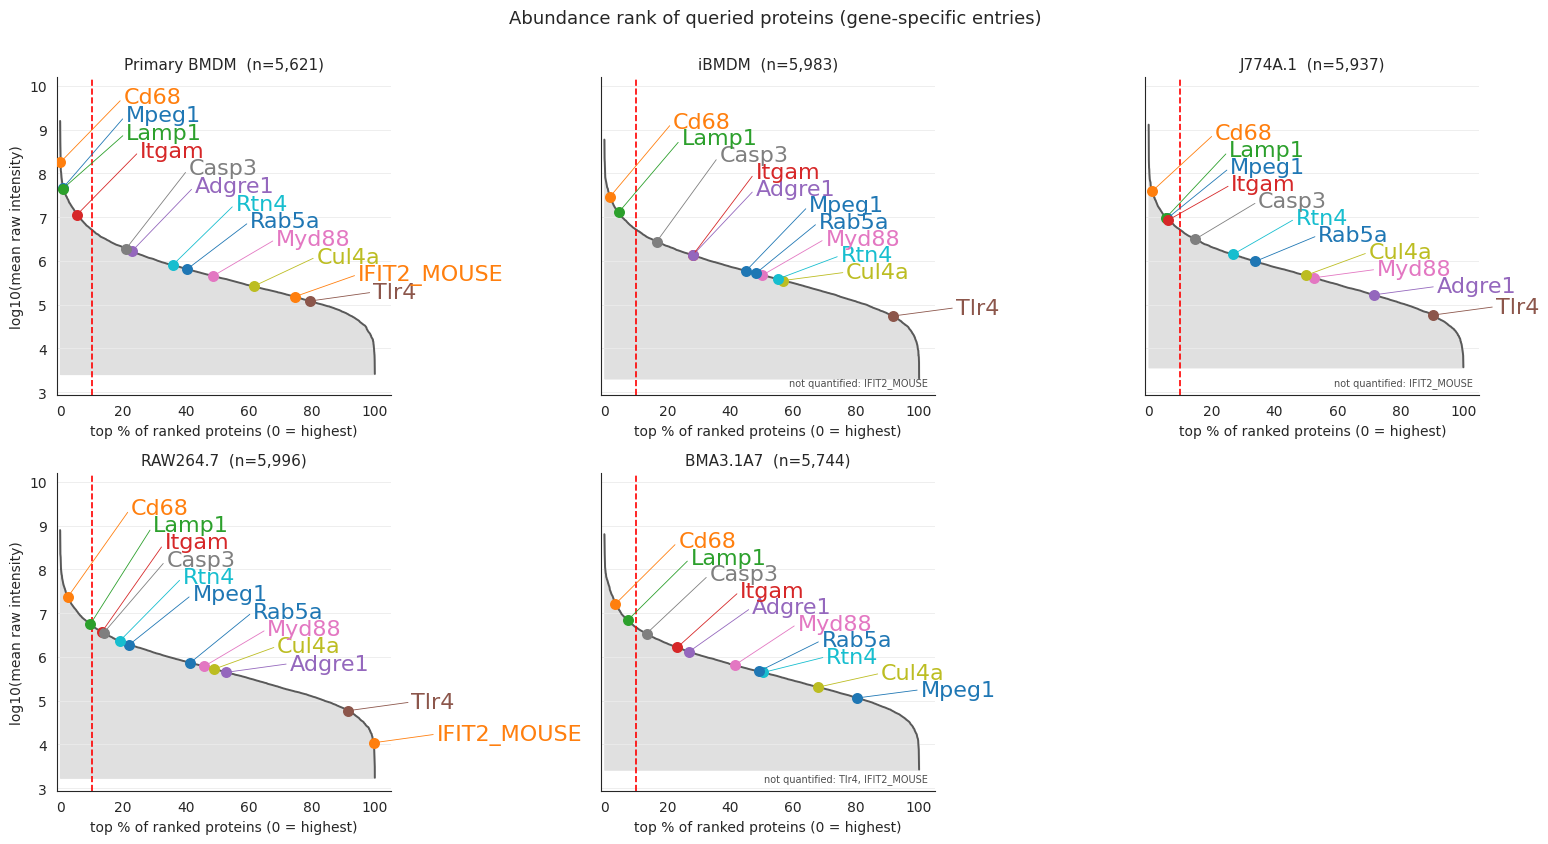

In [7]:
# Percentile x axis: panels share a 0-100 scale even though each line quantified a different number of proteins
query = ["mpeg1", "CD68", "Lamp1", "itgam", "adgre1", "TLR4", "myd88", "casp3",
         "cul4a", "RTN4", "rab5a", "hras", "IFIT2_MOUSE", "notagene"]

##READ THE OUTPUT OF THIS CELL - it will tell you if a gene is not found. Try alternate gene names


fig, axes, _ = plot_abundance_waterfall(proteins, qindex, query, include_groups=False, x_axis="percentile",
                                       label_offset = 20, fontsize=16)

#GROUPS are proteins that are indistinguishable by their peptides (ie two or more proteins that share a peptide which was identified by mass spec)
# keep default at 0 to only list the abundances calculated from unique peptides (peptides that map to just one protein)
# if your protein is not detected with INCLUDE_GROUPS = False, try with INCLUDE_GROUPS = True
INCLUDE_GROUPS = False

# dashed red reference line at the 10th percentile (top 10% most abundant) on every visible panel
for ax in axes:
    if ax.get_visible():
        ax.axvline(10, color="red", ls="--", lw=1.2, zorder=2)

# set save if you want to save the outbook in the colab folder to the left (then you can download it locally)
SAVE = True
if SAVE:                                    # saved after the line is drawn so the PNG includes it
    fig.savefig("waterfall_plotname.png", dpi=300, bbox_inches="tight")
plt.show()

## Plot style 2: Heatmap (raw data or row-normalized)

[info] no entry of its own (1): notagene
[info] 4 shared-group row(s) added via member genes: Cul4a/b, Rab5a/b/c, Hras/Kras/Nras, Hras/Nras


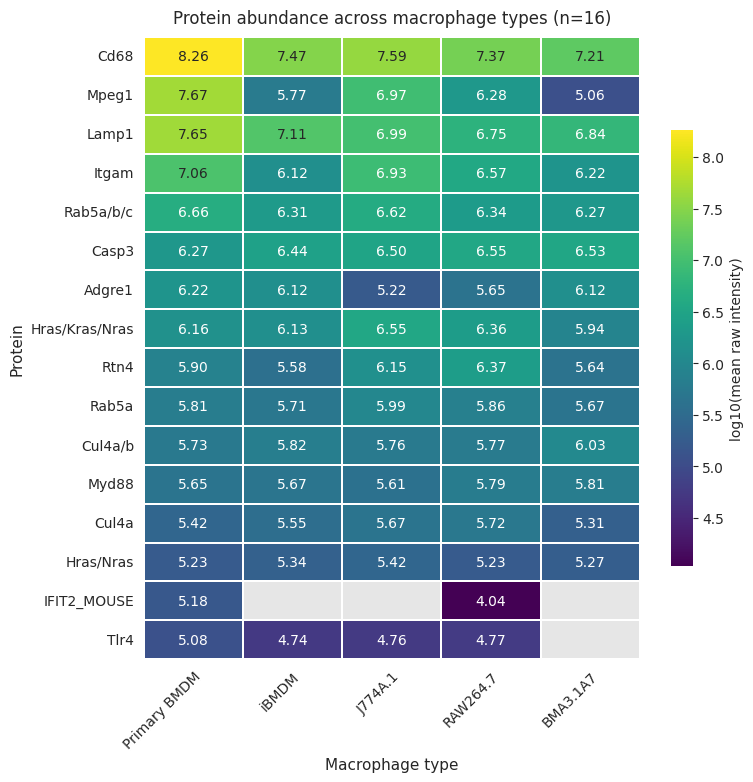

In [8]:
# Plot style 2 : HEATMAP
# Capitalization does not matter. Unmatched entries are reported, not dropped silently.
# Shared groups containing a queried gene are added as their own rows (include_groups=False to omit).
query = ["mpeg1", "CD68", "Lamp1", "itgam", "adgre1", "TLR4", "myd88", "casp3",
         "cul4a", "RTN4", "rab5a", "hras", "IFIT2_MOUSE", "notagene"]

fig, ax, mat = plot_macrophage_heatmap(proteins, qindex, query, sort_by="primary bmdm",
                                       savepath="macrophage_heatmap.png")

# set save if you want to save the outbook in the colab folder to the left (then you can download it locally)
SAVE = True
if SAVE:                                    # saved after the line is drawn so the PNG includes it
    fig.savefig("heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

[info] no entry of its own (2): hras, notagene
[note] 'cul4a' is also in 1 shared group(s), not plotted: Cul4a/b
[note] 'rab5a' is also in 1 shared group(s), not plotted: Rab5a/b/c
[note] 'hras' is also in 2 shared group(s), not plotted: Hras/Kras/Nras, Hras/Nras


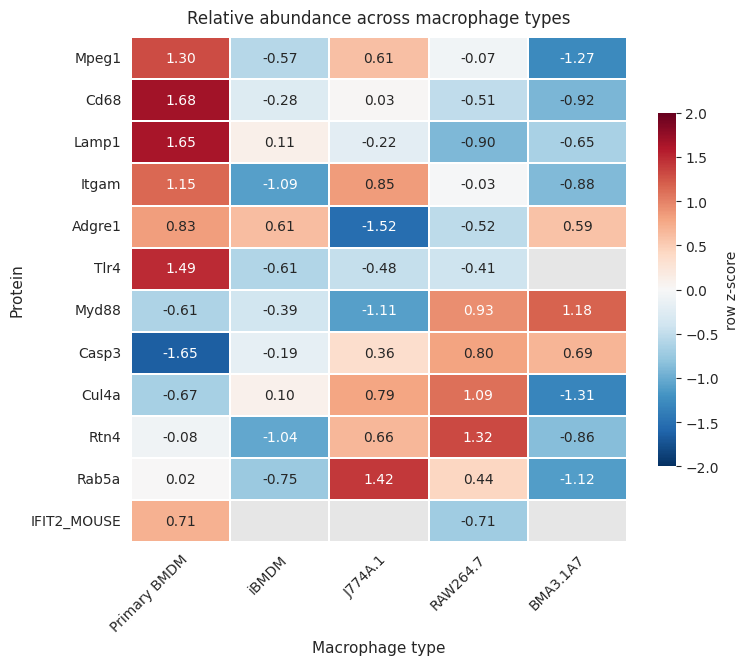

In [9]:
# Row z-scored version, using same query as defined above gene-specific rows only (shared groups listed but not plotted)
fig, ax, mat_z = plot_macrophage_heatmap(proteins, qindex, query, include_groups=False,
                                         zscore=True, vmin=-2, vmax=2,
                                         min_detected=2,
                                         title="Relative abundance across macrophage types",
                                         savepath="macrophage_heatmap_z.png")
# set save if you want to save the outbook in the colab folder to the left (then you can download it locally)
SAVE = True
if SAVE:                                    # saved after the line is drawn so the PNG includes it
    fig.savefig("row_zscored_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
# what each row is (paralog groups, which accession was kept, replicates quantified per line)
describe_matches(proteins, qindex, query)

,label,kind,Gene name,Uniprot Accession,Peptide Count,n_Primary BMDM,n_iBMDM,n_J774A.1,n_RAW264.7,n_BMA3.1A7
0,Mpeg1,single,Mpeg1,A1L314,18,4,4,4,4,4
1,Cd68,single,Cd68,P31996,7,4,4,4,4,4
2,Lamp1,single,Lamp1,P11438,9,4,4,4,4,4
3,Itgam,single,Itgam,P05555,37,4,4,4,4,4
4,Adgre1,single,Adgre1,Q61549,8,4,4,4,4,4
5,Tlr4,single,Tlr4,Q9QUK6,2,4,3,4,4,0
6,Myd88,single,Myd88,P22366,7,4,4,4,4,4
7,Casp3,single,Casp3,P70677,7,4,4,4,4,4
8,Cul4a,single,Cul4a,Q3TCH7,5,4,4,4,4,4
9,Cul4a/b,paralog_group,Cul4a;Cul4b,A2A432;Q3TCH7,9,4,4,4,4,4
